# Berlin Urban Flood — Kaggle Phase 1: Original U-Net Smoke Test & Dataset Inventory

**Purpose:** Verify that Kaggle can (a) fetch the authors' public code, (b) build a faithful version of their 13-channel 256×256 U-Net architecture, (c) run one training epoch on **synthetic** arrays, and (d) inspect the Zenodo archives **without downloading 23.7 GB**.

**Important distinction:** A synthetic smoke test **is not a scientific baseline** and says nothing about flood-prediction accuracy. The original code expects intermediate files such as `x_train_val.npy` and RF `.pkl` tables that are not bundled with the repository. Dataset inventory is the next required step towards a real-data baseline.

References: [Article](https://doi.org/10.5194/nhess-23-809-2023) · [Author's GitHub](https://github.com/omarseleem92/Machine_learning_for_urban_flooding) · [Zenodo data](https://zenodo.org/records/7221058).

**Kaggle setup:** Settings → Accelerator: **GPU T4 ×2** (if offered); Internet: **On**. Run cells top-to-bottom with Shift+Enter. Do **not** download either entire ZIP at this stage.

## 1. Inspect runtime (GPU, TensorFlow, memory)

In [1]:
import os, sys, platform, subprocess, shutil, json, warnings
from pathlib import Path
print('Python:', sys.version.split()[0], '| OS:', platform.platform())
print('Working directory:', os.getcwd())
print('GPU info:')
try:
    r = subprocess.run(['nvidia-smi'], capture_output=True, text=True)
    print(r.stdout[:2500] if r.returncode == 0 else 'GPU not detected: '+r.stderr[:500])
except FileNotFoundError:
    print('nvidia-smi not available; check that a GPU accelerator is enabled.')
print('Disk:', shutil.disk_usage('/kaggle/working') if Path('/kaggle/working').exists() else shutil.disk_usage('/tmp'))
import numpy as np
import tensorflow as tf
print('TensorFlow:', tf.__version__)
print('Detected TF GPUs:', tf.config.list_physical_devices('GPU'))
if not tf.config.list_physical_devices('GPU'):
    print('WARNING: TensorFlow is running without a GPU; enable Accelerator in Kaggle Settings.')

Python: 3.13.15 | OS: Linux-6.18.55+-x86_64-with-glibc2.39
Working directory: /kaggle/working
GPU info:
Mon Nov  2 02:51:36 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.178.04             Driver Version: 580.178.04     CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   43C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                   

## 2. Clone and inspect the **actual author repository**

In [2]:
ROOT=Path('/kaggle/working/berlin_original_repo') if Path('/kaggle/working').exists() else Path('/tmp/berlin_original_repo')
URL='https://github.com/omarseleem92/Machine_learning_for_urban_flooding.git'
if not ROOT.exists():
    p=subprocess.run(['git','clone','--depth','1',URL,str(ROOT)], capture_output=True,text=True)
    if p.returncode: raise RuntimeError('Git clone failed. Enable Internet in Kaggle session. Details: '+p.stderr[:1000])
print('Repository:', ROOT)
for p in sorted(ROOT.rglob('*.ipynb')):
    print(' -',p.relative_to(ROOT), '(', round(p.stat().st_size/1024,1), 'KB)')
commit=subprocess.run(['git','-C',str(ROOT),'rev-parse','HEAD'],capture_output=True,text=True)
GIT_SHA=commit.stdout.strip()
print('Commit SHA:',GIT_SHA)
if len(GIT_SHA)!=40: raise RuntimeError('Could not record Git commit SHA')

Repository: /kaggle/working/berlin_original_repo
 - Code/Convolutional neural network/1- Generate images from points and split the polygons..ipynb ( 3.2 KB)
 - Code/Convolutional neural network/2- Cutting the predictive feature rasters.ipynb ( 6.8 KB)
 - Code/Convolutional neural network/3- Read_cutted_images.ipynb ( 8.7 KB)
 - Code/Convolutional neural network/U-Net.SA1&2.ipynb ( 9.7 KB)
 - Code/Convolutional neural network/U_Net-SA1&2-SA0 (transferred model).ipynb ( 5.9 KB)
 - Code/Random forest/RF-SA1&2-SA0.ipynb ( 13.1 KB)
Commit SHA: 4b6671e4811a2ac71db370cb5c74cda6a0301690


In [3]:
original_unet = ROOT / 'Code/Convolutional neural network/U-Net.SA1&2.ipynb'
original_rf   = ROOT / 'Code/Random forest/RF-SA1&2-SA0.ipynb'
for p in (original_unet,original_rf):
    nb=json.loads(p.read_text(encoding='utf-8'))
    code='\n'.join(''.join(c.get('source',[])) for c in nb['cells'] if c.get('cell_type')=='code')
    print('\n', p.name,'| cells:',len(nb['cells']))
    for marker in ['x_train_val.npy','df_hotspot1_RF_train.pkl','n_jobs=30','period=1','D:\\']:
        if marker in code: print('   Found:',repr(marker))
print('This is source inspection. We do not execute the original notebook blindly.')


 U-Net.SA1&2.ipynb | cells: 11
   Found: 'x_train_val.npy'
   Found: 'period=1'

 RF-SA1&2-SA0.ipynb | cells: 54
   Found: 'df_hotspot1_RF_train.pkl'
   Found: 'n_jobs=30'
   Found: 'D:\\'
This is source inspection. We do not execute the original notebook blindly.


### Read original notebook source
The next cell prints selected cells from the **original GitHub notebooks** for inspection. It does not execute the author code.

In [4]:
for path, chosen in [(original_unet, [1, 3, 7, 8]), (original_rf, [2, 13, 15, 18, 21])]:
    src = json.loads(path.read_text(encoding='utf-8'))
    print("\nORIGINAL SOURCE:", path.name)
    for index in chosen:
        c = src['cells'][index]
        fragment = ''.join(c.get('source', []))
        print("\n--- Original cell", index, "---")
        print(fragment[:1200] + ("\n... (truncated)" if len(fragment)>1200 else ""))


ORIGINAL SOURCE: U-Net.SA1&2.ipynb

--- Original cell 1 ---
x_train_val=np.load('x_train_val.npy')
y_train_val=np.load('y_train_val.npy')

--- Original cell 3 ---
#Build the model
# The input array shape is (number of training images, IMG_WIDTH, IMG_HEIGHT, IMG_CHANNELS). 
# We used 256 x 256 image size and 13 img channels which represent the 13 predictive features
inputs = tf.keras.layers.Input((IMG_HEIGHT, IMG_WIDTH, IMG_CHANNELS))
#s = tf.keras.layers.Lambda(lambda x: x / 255)(inputs)


--- Original cell 7 ---
model = tf.keras.Model(inputs=[inputs], outputs=[outputs])


optimizer = tf.keras.optimizers.Adam(beta_1=0.9, beta_2=0.999, epsilon=1e-07, amsgrad=False, name='Adam')

model.compile(optimizer=optimizer, loss=['mse'], loss_weights=[1],metrics=['accuracy'])
model.summary()

--- Original cell 8 ---
#Modelcheckpoint
from keras.callbacks import ModelCheckpoint, EarlyStopping,TensorBoard
from datetime import datetime
start_time = datetime.now()
NAME="U_Net_SA1&2"
checkpointer = Mod

## 3. Rebuild the U-Net described in the authors' notebook

The architecture below preserves the essential published **U-Net.SA1&2.ipynb** structure: **13 input channels, 256×256, filters 32→64→128→256→512, two convolutions per block, BatchNormalization, LeakyReLU(0.2), Dropout(0.5), average pooling, transposed-convolution decoder, and linear 1-channel output**. It replaces obsolete argument names and omits the original `accuracy` metric (inappropriate for regression). It does **not** claim identical weights or reproduce the published results.

In [5]:
from tensorflow.keras import layers as L

def conv_block(x, n_filters):
    for _ in range(2):
        x=L.Conv2D(n_filters,3,padding='same',kernel_initializer='he_normal',use_bias=False)(x)
        x=L.BatchNormalization()(x)
        x=L.LeakyReLU(negative_slope=0.2)(x)
        x=L.Dropout(0.5)(x)
    return x

def build_original_style_unet():
    inputs=L.Input(shape=(256,256,13))
    x=inputs; skips=[]
    for filters in (32,64,128,256):
        x=conv_block(x,filters)
        skips.append(x)
        x=L.AveragePooling2D((2,2))(x)
    x=conv_block(x,512)
    for filters,skip in zip((256,128,64,32),reversed(skips)):
        x=L.Conv2DTranspose(filters,(2,2),strides=(2,2),padding='same')(x)
        x=L.Concatenate()([x,skip])
        x=conv_block(x,filters)
    outputs=L.Conv2D(1,(1,1),padding='same')(x)
    return tf.keras.Model(inputs,outputs,name='berlin_unet_original_style')

tf.keras.utils.set_random_seed(42)
model=build_original_style_unet()
model.compile(optimizer=tf.keras.optimizers.Adam(),loss='mse',metrics=[tf.keras.metrics.RootMeanSquaredError(name='rmse')])
print('Input:',model.input_shape,'Output:',model.output_shape,'Parameters:',model.count_params())
assert model.input_shape[1:]==(256,256,13)
assert model.output_shape[1:]==(256,256,1)
model.summary()

I0000 00:00:1793587918.050286      24 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1793587918.054003      24 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Input: (None, 256, 256, 13) Output: (None, 256, 256, 1) Parameters: 7771809


Model: "berlin_unet_original_style"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 256, 256,  │          0 │ -                 │
│ (InputLayer)        │ 13)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 256, 256,  │      3,744 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 256, 256,  │        128 │ conv2d[0][0]      │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ leaky_re_lu         │ (None, 256, 256,  │          0 │ batch_normalizat… │
│ (LeakyReLU)         │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 256, 256,  │          0 │ leaky_re_lu[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 256, 256,  │      9,216 │ dropout[0][0]     │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 256, 256,  │        128 │ conv2d_1[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ leaky_re_lu_1       │ (None, 256, 256,  │          0 │ batch_normalizat… │
│ (LeakyReLU)         │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 256, 256,  │          0 │ leaky_re_lu_1[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ average_pooling2d   │ (None, 128, 128,  │          0 │ dropout_1[0][0]   │
│ (AveragePooling2D)  │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 128, 128,  │     18,432 │ average_pooling2… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128, 128,  │        256 │ conv2d_2[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ leaky_re_lu_2       │ (None, 128, 128,  │          0 │ batch_normalizat… │
│ (LeakyReLU)         │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 128, 128,  │          0 │ leaky_re_lu_2[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 128, 128,  │     36,864 │ dropout_2[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128, 128,  │        256 │ conv2d_3[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ leaky_re_lu_3       │ (None, 128, 128,  │          0 │ batch_normalizat

 Total params: 7,771,809 (29.65 MB)

 Trainable params: 7,765,921 (29.62 MB)

 Non-trainable params: 5,888 (23.00 KB)

## 4. GPU training smoke test — **synthetic data only**

Runs **one epoch** on four fake 256×256×13 rasters. Here the target is artificially constructed from the input so this is only a software/hardware test. The RMSE below is not a flood-science result.

In [6]:
import time
rng=np.random.default_rng(42)
N=4
x=rng.normal(0,0.25,size=(N,256,256,13)).astype('float32')
rainfall=(np.arange(N,dtype='float32')+2)*0.2
x[:,:,:,12]=rainfall[:,None,None]
y=np.maximum(0,0.15*x[:,:,:,0]+0.05*x[:,:,:,1]+0.2*x[:,:,:,12]).astype('float32')[...,None]
print('x:',x.shape,'y:',y.shape,'ranges:',(np.min(x),np.max(x)),(np.min(y),np.max(y)))
t0=time.time()
history=model.fit(x[:3],y[:3],validation_data=(x[3:],y[3:]),epochs=1,batch_size=1,verbose=2)
print('Smoke-test training completed in',round(time.time()-t0,1),'seconds')
pred=model.predict(x[3:4],batch_size=1,verbose=0)
print('Predictions:', pred.shape,'| finite:',bool(np.isfinite(pred).all()))
assert np.isfinite(pred).all()
print('PASS: U-Net forward/backward on Kaggle. This is NOT a real-data baseline.')

x: (4, 256, 256, 13) y: (4, 256, 256, 1) ranges: (np.float32(-1.2714359), np.float32(1.3279604)) (np.float32(0.0), np.float32(0.36768812))


2026-11-02 02:52:14.693814: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-02 02:52:14.887533: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-02 02:52:16.409363: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-02 02:52:16.705990: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-02 02:52:17.473884: E external/local_xla/xla/stream_

3/3 - 36s - 12s/step - loss: 2.6027 - rmse: 1.6133 - val_loss: 0.5525 - val_rmse: 0.7433
Smoke-test training completed in 36.6 seconds
Predictions: (1, 256, 256, 1) | finite: True
PASS: U-Net forward/backward on Kaggle. This is NOT a real-data baseline.


## 5. Save evidence of the test

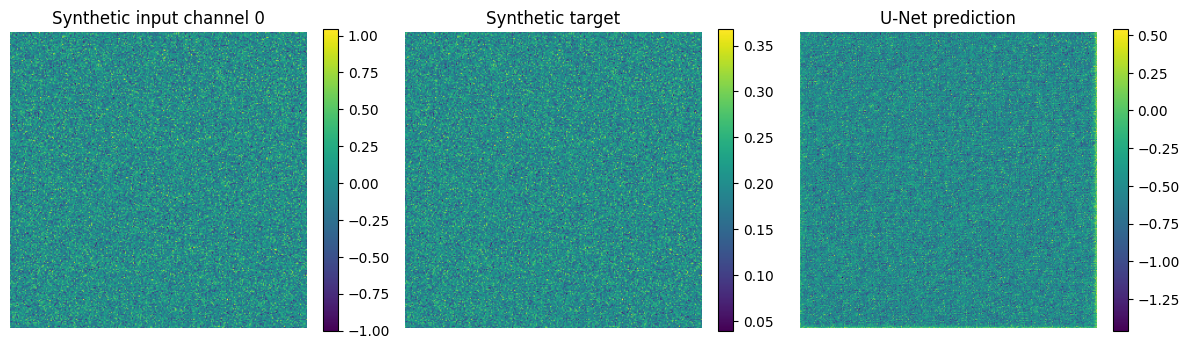

Saved: /kaggle/working/berlin_unet_smoke.keras 
 /kaggle/working/berlin_smoke_result.json 
 /kaggle/working/berlin_smoke_preview.png


In [7]:
import matplotlib.pyplot as plt
OUT=Path('/kaggle/working') if Path('/kaggle/working').exists() else Path('/tmp')
model_path=OUT/'berlin_unet_smoke.keras'
model.save(model_path)
result={
  'status':'SYNTHETIC_SMOKE_TEST_ONLY',
  'source_repo':URL,'commit_sha':GIT_SHA,
  'tensorflow':tf.__version__,
  'gpu':[g.name for g in tf.config.list_physical_devices('GPU')],
  'input_shape':list(model.input_shape),'output_shape':list(model.output_shape),
  'parameters':int(model.count_params()),
  'history':{k:list(map(float,v)) for k,v in history.history.items()}
}
(OUT/'berlin_smoke_result.json').write_text(json.dumps(result,indent=2),encoding='utf-8')
fig,axes=plt.subplots(1,3,figsize=(12,3.5))
for ax,arr,title in zip(axes,[x[3,:,:,0],y[3,:,:,0],pred[0,:,:,0]],['Synthetic input channel 0','Synthetic target','U-Net prediction']):
    im=ax.imshow(arr,cmap='viridis'); ax.set_title(title); ax.axis('off');fig.colorbar(im,ax=ax,fraction=0.046)
plt.tight_layout();fig.savefig(OUT/'berlin_smoke_preview.png',dpi=130);plt.show()
print('Saved:',model_path, '\n',OUT/'berlin_smoke_result.json','\n',OUT/'berlin_smoke_preview.png')

## 6. Inspect Zenodo metadata (no big files downloaded)

The archives are around 20.8 GB and 2.9 GB, respectively. **Do not run `wget` on the full ZIPs for this first test.** We only retrieve a small JSON metadata response.

In [8]:
import requests
api='https://zenodo.org/api/records/7221058'
try:
    response=requests.get(api,timeout=40)
    response.raise_for_status()
    metadata=response.json()
    files=metadata.get('files',[])
    for f in files:
        print(f.get('key'),round(f.get('size',0)/1e9,3),'GB', 'checksum:',f.get('checksum'))
    if not files: print('No files returned; inspect record in browser.')
except Exception as e:
    print('Zenodo metadata lookup failed:',repr(e))
    print('Open https://zenodo.org/records/7221058 in a browser.')

Water_depth_TELEMAC_2D.zip 2.907 GB checksum: md5:3ae2d4a372afd48e044cee8a393193f9
Predictive_features.zip 20.764 GB checksum: md5:cb2c25df042cc2df13cb23fb0732b763


## 7. Inspect ZIP *filenames* with HTTP Range (optional, no full archive)

This uses [`remotezip`](https://pypi.org/project/remotezip/). It only works when Zenodo's chosen download URL correctly supports HTTP `Range` requests. If a request fails or the ZIP format is unsupported, the cell **reports the error and stops** rather than downloading 23.7 GB.

The objective is to discover what is actually inside the two ZIPs so that a trustworthy geospatial preprocessing pipeline can be written. Logs are saved to `/kaggle/working/berlin_archive_manifest.csv`.

In [9]:
import importlib.util
if importlib.util.find_spec('remotezip') is None:
    try:
        p=subprocess.run([sys.executable,'-m','pip','install','-q','remotezip'],capture_output=True,text=True,timeout=120)
        if p.returncode: print('remotezip install failed:',p.stderr[-900:])
        else: print('remotezip installed')
    except Exception as e: print('remotezip install failed:',repr(e))

remotezip installed


In [10]:
from collections import Counter
import pandas as pd
manifest_rows=[]
if importlib.util.find_spec('remotezip') is None:
    print('Skipping remote ZIP listing: remotezip not installed.')
else:
    from remotezip import RemoteZip
    for archive in ('Predictive_features.zip','Water_depth_TELEMAC_2D.zip'):
        url=f'https://zenodo.org/records/7221058/files/{archive}?download=1'
        print('\nListing remote ZIP:',archive)
        try:
            with RemoteZip(url,timeout=90) as z:
                infos=z.infolist()
                print('Total members:',len(infos))
                print('Extensions:',Counter(Path(i.filename).suffix.lower() for i in infos).most_common(12))
                for item in infos[:35]:
                    print(' ',item.filename,'| uncompressed',round(item.file_size/1e6,2),'MB')
                manifest_rows.extend(dict(archive=archive,path=i.filename,compressed_bytes=i.compress_size,uncompressed_bytes=i.file_size) for i in infos)
        except Exception as e:
            print('Remote range listing unsuccessful:',type(e).__name__,str(e)[:600])
            print('Do NOT switch to downloading the entire ZIP just to list files.')
if manifest_rows:
    manifest=pd.DataFrame(manifest_rows)
    dest=OUT/'berlin_archive_manifest.csv'
    manifest.to_csv(dest,index=False)
    print('Saved manifest:',dest,'| members:',len(manifest))
else:
    print('No manifest generated. Source ZIP layout still needs verification.')


Listing remote ZIP: Predictive_features.zip
Total members: 12
Extensions: [('.tif', 12)]
  CN.tif | uncompressed 31.59 MB
  Cos_Aspect.tif | uncompressed 6926.33 MB
  Curvature.tif | uncompressed 6924.64 MB
  DEM_berlin_boundary.tif | uncompressed 1311.6 MB
  DEM_depth_1m_clip.tif | uncompressed 515.64 MB
  DEM_L.tif | uncompressed 6926.33 MB
  flow_acc_comb_nodata_clipped.tif | uncompressed 977.19 MB
  roughness_final_berlin.tif | uncompressed 7077.35 MB
  Sin_Aspect.tif | uncompressed 6926.33 MB
  Slope_degree.tif | uncompressed 6926.33 MB
  TPI_nan.tif | uncompressed 6924.64 MB
  TWI_Low_pass_filter_berlin_boundary.tif | uncompressed 3841.48 MB

Listing remote ZIP: Water_depth_TELEMAC_2D.zip
Total members: 42
Extensions: [('.tif', 42)]
  SA0/100mm.tif | uncompressed 100.48 MB
  SA0/110mm.tif | uncompressed 100.28 MB
  SA0/120mm.tif | uncompressed 100.28 MB
  SA0/130mm.tif | uncompressed 100.28 MB
  SA0/140mm.tif | uncompressed 100.3 MB
  SA0/150mm.tif | uncompressed 100.3 MB
  SA0/

## 8. Optional: check for preprocessed *real* datasets already attached to Kaggle

These preprocessed inputs (`.npy`, `.pkl`) are referred to by the published notebooks, **but are not guaranteed to be included in the Zenodo ZIPs**. We do not auto-execute untrusted pickle files. This cell only lists candidate names.

In [11]:
input_dir=Path('/kaggle/input')
if input_dir.exists():
    matches=[]
    for p in input_dir.rglob('*'):
        if p.is_file() and (p.name.lower() in {'x_train_val.npy','y_train_val.npy','df_hotspot1_rf_train.pkl','df_hotspot2_rf_train.pkl','df_hotspot1_rf_test.pkl','df_hotspot2_rf_test.pkl'}):
            matches.append(p)
    if matches:
        print('Preprocessed candidates:')
        for p in matches: print(' ',p)
    else:
        print('No published-notebook intermediate .npy/.pkl filenames found in attached Kaggle inputs.')
else: print('No /kaggle/input directory detected.')
print('\nFINISHED PHASE 1. Report back: GPU info, PASS/ERROR, and berlin_archive_manifest.csv (if created).')

No published-notebook intermediate .npy/.pkl filenames found in attached Kaggle inputs.

FINISHED PHASE 1. Report back: GPU info, PASS/ERROR, and berlin_archive_manifest.csv (if created).


## 9. What remains for a **real** Berlin baseline?

1. Use the actual archive manifest to map **12 spatial predictors + rainfall** to **TELEMAC water-depth targets**. Confirm CRS, raster bounds, pixel resolution, missing values, units, and rainfall event naming.
2. Reproduce the **SA1/SA2 training and SA0 unseen-area evaluation** protocol, including rain-event holdouts. Avoid splitting neighboring spatial patches naively across train/test.
3. Store processed samples in an efficient, lazy-read format; do not load tens of GB into Kaggle RAM. Preserve provenance and group identifiers.
4. **First real-data baseline:** train RandomForestRegressor on a bounded subset of real pixels (document sample size and differences from paper), then calculate RMSE/NSE and flood CSI. Next train the U-Net on genuine patches.
5. Only compare results to the paper when original data preprocessing, splits, hyperparameters and targets have been verified. Changes to these conditions should be labeled as adaptations.

**The phase-1 notebook stops deliberately before making scientific claims.** The next step is driven by the verified ZIP manifest, not guessed filenames or fabricated data.